In [4]:
import pandas as pd 

df = pd.read_csv( r'C:\Users\mobil\Desktop\customer-churn-prediction\data\raw\telco_churn.csv')

print(df.shape)
display(df.head())

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [ ]:
df['Churn'].value_counts()

df["Churn"].value_counts(normalize=True)

Churn
0    5163
1    1869
Name: count, dtype: int64

In [34]:
df['TotalCharges'].head(10)
df["TotalCharges"].dtype

dtype('float64')

In [9]:
df['TotalCharges'].eq("").sum()
df['TotalCharges'].str.strip().eq("").sum()

np.int64(11)

In [10]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [11]:
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isna().sum())

float64
11


In [12]:
df = df.dropna(subset=['TotalCharges'])

In [13]:
print(df.shape)
print(df['TotalCharges'].isna().sum())

(7032, 21)
0


In [15]:
df =df.drop(columns=['customerID'])

In [16]:
print(df.shape)
print(df.columns.tolist())

(7032, 20)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [17]:
df.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [21]:
df.select_dtypes(include='number').columns.tolist()

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [22]:
df['Churn'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

In [23]:
df['Churn'].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [24]:
numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

categorical_features = [
    col for col in df.columns
    if col not in numerical_features + ['Churn']
]



In [25]:
for col in categorical_features:
    print(col, '->', df[col].nunique()) 

gender -> 2
SeniorCitizen -> 2
Partner -> 2
Dependents -> 2
PhoneService -> 2
MultipleLines -> 3
InternetService -> 3
OnlineSecurity -> 3
OnlineBackup -> 3
DeviceProtection -> 3
TechSupport -> 3
StreamingTV -> 3
StreamingMovies -> 3
Contract -> 3
PaperlessBilling -> 2
PaymentMethod -> 4


In [28]:
for col in categorical_features:
    print('\n', col)
    print(df[col].value_counts())


 gender
gender
Male      3549
Female    3483
Name: count, dtype: int64

 SeniorCitizen
SeniorCitizen
0    5890
1    1142
Name: count, dtype: int64

 Partner
Partner
No     3639
Yes    3393
Name: count, dtype: int64

 Dependents
Dependents
No     4933
Yes    2099
Name: count, dtype: int64

 PhoneService
PhoneService
Yes    6352
No      680
Name: count, dtype: int64

 MultipleLines
MultipleLines
No                  3385
Yes                 2967
No phone service     680
Name: count, dtype: int64

 InternetService
InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

 OnlineSecurity
OnlineSecurity
No                     3497
Yes                    2015
No internet service    1520
Name: count, dtype: int64

 OnlineBackup
OnlineBackup
No                     3087
Yes                    2425
No internet service    1520
Name: count, dtype: int64

 DeviceProtection
DeviceProtection
No                     3094
Yes                    2418
No intern

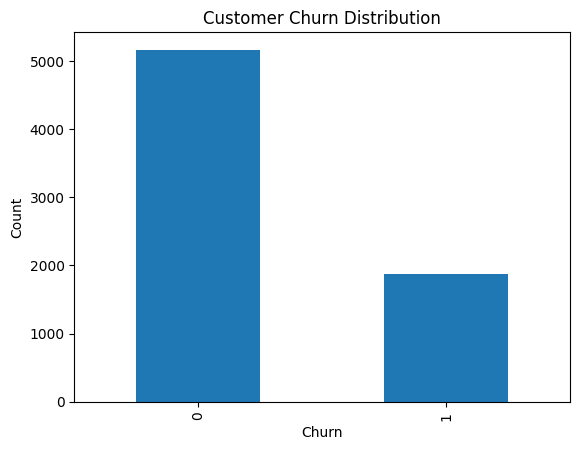

In [29]:
import matplotlib.pyplot as plt

df['Churn'].value_counts().plot(kind='bar')

plt.title('Customer Churn Distribution')
plt.xlabel("Churn")
plt.ylabel('Count')

plt.show()

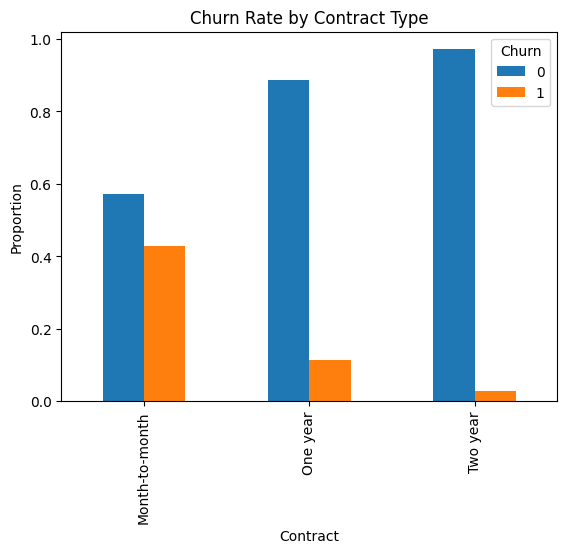

In [30]:
pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
).plot(kind='bar')

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract')
plt.ylabel('Proportion')

plt.show()

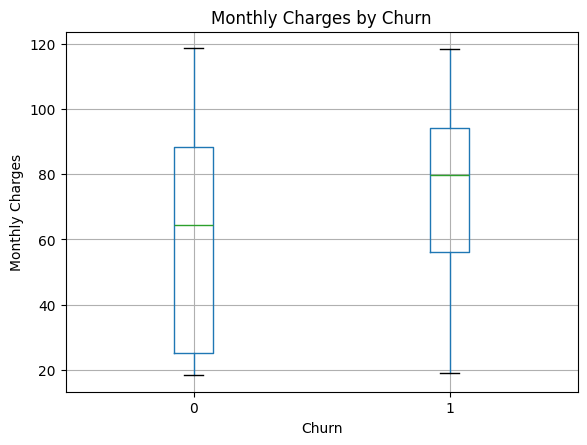

In [32]:
df.boxplot(
    column='MonthlyCharges',
    by='Churn'
)

plt.title('Monthly Charges by Churn')
plt.suptitle("")
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()